# Nhóm 10 – Dự đoán tái nhập viện ở bệnh nhân đái tháo đường (Diabetes 130-US)
**Notebook tổng hợp:** chạy **script của từng thành viên, lấy trực tiếp từ nhánh của người đó**, theo thứ tự từ trên xuống. Các bước nối với nhau bằng file trong `output/`: output của bước trước là input của bước sau. `Runtime → Run all` là chạy cả pipeline.

| Bước | Task | Người | Script (nhánh) | Đọc | Ghi (`output/`) |
|---|---|---|---|---|---|
| 01 | Bỏ thuộc tính định danh | Dũng | `src/01_explore_and_drop_ids.py` (Dung) | `data/diabetic_data.csv` | `step1.csv`, `step1_patient_nbr.csv` |
| 02 | Thống kê khuyết, bỏ cột khuyết > 50% | Sơn | `src/02_missing_stats_and_filter.py` (Son) | `step1.csv` | `step2.csv`, `missing_rate.csv` |
| 03 | Bỏ dòng khuyết < 2%, tạo nhãn, chia 80/20 | Chiến | `src/03_data_preprocessing_splitting.py` (Chien) | `step2.csv`, `step1_patient_nbr.csv` | `train.csv`, `test.csv` |
| 04 | One-Hot (fit trên train) | Dũng | `src/04_one_hot_encoding.py` (Dung) | `train.csv`, `test.csv` | `X_train_onehot.npz`, `X_test_onehot.npz`, `onehot_columns.txt`, `y_train.csv`, `y_test.csv` |
| 05 | PCA 60 thành phần | Sơn | `src/05_pca.py` (Son) | `X_*_onehot.npz`, `onehot_columns.txt` | `X_train_pca.npy`, `X_test_pca.npy`, `pca_eigenvalues.npy`, `pca_components.npy`, `pca_feature_names.txt` |
| 06 | Chuẩn hóa sau PCA, scree plot, top 5 vector riêng | Chiến | `src/06_feature_scaling_pca_analysis.py` (Chien) | `X_*_pca.npy`, `pca_*` | `X_train_pca_scaled.npy`, `X_test_pca_scaled.npy`, `eigenvalues.png` |
| 07a | k-NN tự cài, PCA chưa vs đã chuẩn hóa | Dũng | `src/07a_knn.py` (Dung) | `X_*_pca*.npy`, `y_*.csv` | `knn_results.csv`, `knn_k_curve.png` |
| 07b | Softmax Regression tự cài, chưa vs đã chuẩn hóa | Dũng | `src/07b_softmax_regression.py` (Dung) | `X_*_pca*.npy`, `y_*.csv` | `softmax_results.csv`, `softmax_loss.png` |
| 10 | Test Accuracy multi-class, ma trận nhầm lẫn | Dũng | `src/10_evaluation.py` (Dung) | `pred_*.npy`, `y_test.csv` | `accuracy_summary.csv`, `confusion_*.csv`, `confusion_matrices.png` |



**Quy ước:** mọi script chạy từ thư mục gốc dự án, đọc/ghi đúng tên file trong bảng; không đổi tên khi chưa báo cả nhóm. Các bước học từ dữ liệu chỉ fit trên train. `random_state = 42`. Muốn sửa một bước thì sửa script trên nhánh của mình rồi push, chạy lại notebook là cập nhật.

## 0. Cài đặt
Clone cả ba nhánh vào `branches/`. Thư mục làm việc là `branches/Dung` (có dữ liệu gốc); script của Sơn và Chiến được gọi qua `../Son/src/...`, `../Chien/src/...` nên cùng đọc/ghi một thư mục `output/`.

In [1]:
REPO = "https://github.com/chiensondung/HCMUT-AnIntroductiontoMachineLearningandApplication-Project.git"
%cd /content
!rm -rf /content/branches
for b in ["main", "Dung", "Son", "Chien"]:
    !git clone -q -b {b} {REPO} /content/branches/{b}
    !git -C /content/branches/{b} log -1 --format="{b}: %h %an %ad %s" --date=short
%cd /content/branches/main
!pip -q install -r ../Dung/requirements.txt -r ../Son/requirements.txt -r ../Chien/requirements.txt

/content
main: ffd4435 Trịnh Hoàng Dũng 2026-11-13 Được tạo bằng Colab
Dung: ee503bc hdung274520 2026-11-13 Tách đánh giá ra bước 10: 07a/07b lưu nhãn dự đoán, 10 tính Test Accuracy và vẽ ma trận nhầm lẫn
Son: 4a8ee67 chiensondung 2026-11-09 Dong bo buoc 02, 05 theo bo ten file chung trong output/
Chien: 55d5328 Ho Ba Chien 2026-11-09 Colab
/content/branches/main


## Giai đoạn 1: Khảo sát và xử lý dữ liệu khuyết

### Bước 01: Bỏ thuộc tính định danh *(Dũng)*

In [2]:
!python ../Dung/src/01_explore_and_drop_ids.py

Kích thước gốc: (101766, 50)

Khảo sát cột định danh:
   encounter_id  patient_nbr payer_code
0       2278392      8222157        NaN
1        149190     55629189        NaN
2         64410     86047875        NaN
3        500364     82442376        NaN
4         16680     42519267        NaN
Số giá trị khác nhau:
 encounter_id    101766
patient_nbr      71518
payer_code          17
dtype: int64
Tỉ lệ khuyết (%):
 encounter_id     0.00
patient_nbr      0.00
payer_code      39.56
dtype: float64

Kích thước sau khi bỏ định danh: (101766, 47)


### Bước 02: Thống kê khuyết, bỏ cột khuyết > 50% *(Sơn)*

In [3]:
!python ../Son/src/02_missing_stats_and_filter.py

weight               96.86
max_glu_serum        94.75
A1Cresult            83.28
medical_specialty    49.08
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64

Bỏ (khuyết >50%): ['weight', 'max_glu_serum', 'A1Cresult']
Kích thước: (101766, 44)


### Bước 03: Bỏ dòng khuyết < 2%, tạo nhãn, chia train/test 80/20 *(Chiến)*

In [4]:
!python ../Chien/src/03_data_preprocessing_splitting.py

Kích thước step2: (101766, 44)
Cột khuyết <2%: ['diag_1', 'diag_2', 'diag_3'] | xóa 1522 dòng
Kích thước sau xử lý: (100244, 45) | train: 79726 | test: 20518
train {'NO': 0.5381, '>30': 0.3503, '<30': 0.1116} | y_bin=1: 0.4619
test {'NO': 0.5323, '>30': 0.353, '<30': 0.1147} | y_bin=1: 0.4677
Còn khuyết: {'race': 2191, 'medical_specialty': 49482}


## Giai đoạn 2: One-Hot, PCA, chuẩn hóa

### Bước 04: One-Hot Encoding *(Dũng)*

In [5]:
!python ../Dung/src/04_one_hot_encoding.py

Train: (79726, 45) | Test: (20518, 45)
Số biến phân loại: 35
Biến số giữ nguyên: ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']
diag_3                      761
diag_2                      716
diag_1                      697
medical_specialty            71
discharge_disposition_id     26
admission_source_id          17
age                          10
admission_type_id             8
dtype: int64

Số cột One-Hot: 2388
diag_1 -> 697 cột
diag_2 -> 716 cột
diag_3 -> 761 cột
Mỗi dòng train có đúng 35 số 1: True

Đã lưu X_train: (79726, 2396) | X_test: (20518, 2396)


### Bước 05: PCA 60 thành phần trên ma trận tương quan *(Sơn)*

In [6]:
!python ../Son/src/05_pca.py

One-Hot + số (train): (79726, 2396) | (test): (20518, 2396)
Bỏ 0 cột phương sai 0 trên train: []
Số chiều sau khi bỏ cột phương sai 0: 2396

Tỉ lệ phương sai giải thích bởi 60 thành phần: 0.0563
Số thành phần cần để đạt 95%: 2115
Kiểm tra trên mẫu 8000 dòng: lệch tối đa trị riêng so với sklearn.PCA = 2.03e-13

Đã lưu Z_train: (79726, 60) | Z_test: (20518, 60)


### Bước 06: Chuẩn hóa sau PCA, biểu đồ Eigenvalues, top 5 vector riêng *(Chiến)*

In [7]:
!python ../Chien/src/06_feature_scaling_pca_analysis.py

X_train_pca: (79726, 60) | X_test_pca: (20518, 60) | components: (2396, 60)
60 thành phần giải thích 5.63% phương sai

PC1: eigenvalue = 4.8591, giải thích 0.20% phương sai
       dac_trung  trong_so
       change_No    0.3839
       change_Ch   -0.3839
  diabetesMed_No    0.3618
 diabetesMed_Yes   -0.3618
      insulin_No    0.2756
    metformin_No    0.1904
 num_medications   -0.1854
metformin_Steady   -0.1741
      insulin_Up   -0.1423
    insulin_Down   -0.1418

PC2: eigenvalue = 4.3718, giải thích 0.18% phương sai
                dac_trung  trong_so
    admission_source_id_7    0.3591
      admission_type_id_1    0.3492
    admission_source_id_1   -0.3417
      admission_type_id_3   -0.3065
       num_lab_procedures    0.1863
         number_diagnoses    0.1609
           num_procedures   -0.1554
medical_specialty_Missing    0.1276
               diag_1_715   -0.1266
               diag_1_414   -0.1182

PC3: eigenvalue = 4.0000, giải thích 0.17% phương sai
                      da

### Kết quả Giai đoạn 2

total 145316
drwxr-xr-x 2 root root     4096 Nov 13 04:52 .
drwxr-xr-x 5 root root     4096 Nov 13 04:50 ..
-rw-r--r-- 1 root root    88405 Nov 13 04:52 eigenvalues.png
-rw-r--r-- 1 root root      128 Nov 13 04:50 missing_rate.csv
-rw-r--r-- 1 root root    29647 Nov 13 04:51 onehot_columns.txt
-rw-r--r-- 1 root root  1150208 Nov 13 04:52 pca_components.npy
-rw-r--r-- 1 root root    19296 Nov 13 04:52 pca_eigenvalues.npy
-rw-r--r-- 1 root root    29647 Nov 13 04:52 pca_feature_names.txt
-rw-r--r-- 1 root root 16022063 Nov 13 04:50 step1.csv
-rw-r--r-- 1 root root   908183 Nov 13 04:50 step1_patient_nbr.csv
-rw-r--r-- 1 root root 15626044 Nov 13 04:50 step2.csv
-rw-r--r-- 1 root root  3189456 Nov 13 04:50 test.csv
-rw-r--r-- 1 root root 12403625 Nov 13 04:50 train.csv
-rw-r--r-- 1 root root   514538 Nov 13 04:51 X_test_onehot.npz
-rw-r--r-- 1 root root  9848768 Nov 13 04:52 X_test_pca.npy
-rw-r--r-- 1 root root  9848768 Nov 13 04:52 X_test_pca_scaled.npy
-rw-r--r-- 1 root root  1997542 N

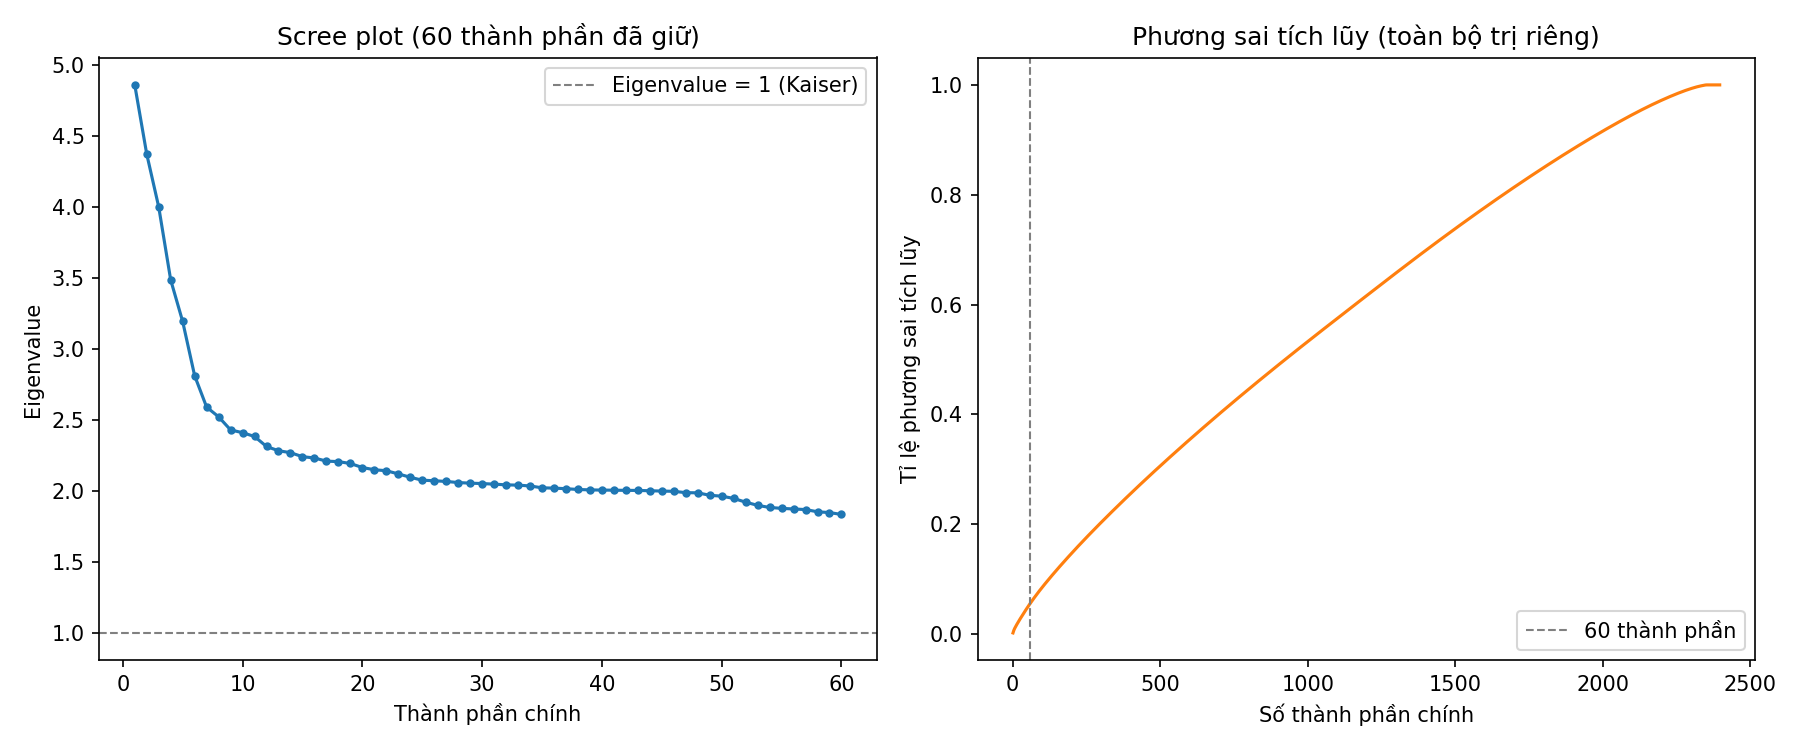

In [8]:
from IPython.display import Image, display
!ls -la output
display(Image("output/eigenvalues.png"))

## Giai đoạn 3: Huấn luyện mô hình

###Bước 07a: Lập trình và tối ưu k-NN (trên dữ liệu chưa chuẩn hoá và đã chuẩn hoá) *(Dũng)*

In [9]:
!python ../Dung/src/07a_knn.py

{'mode': 'chua_chuan_hoa', 'best_k': 5, 'val_macro_f1': 0.3898718834792314, 'test_accuracy': 0.4864021834486792, 'test_macro_f1': 0.37999466868345233, 'test_f1_<30': np.float64(0.12903225806451613), 'test_f1_>30': np.float64(0.4142059058260176), 'test_f1_NO': np.float64(0.5967458421598233)}
{'mode': 'da_chuan_hoa', 'best_k': 9, 'val_macro_f1': 0.3914419798365248, 'test_accuracy': 0.5112584072521689, 'test_macro_f1': 0.37188377247095383, 'test_f1_<30': np.float64(0.0748663101604278), 'test_f1_>30': np.float64(0.4148884745528624), 'test_f1_NO': np.float64(0.6258965326995714)}


### Bước 07b: Softmax Regression, chưa chuẩn hóa vs đã chuẩn hóa *(Dũng)*


In [10]:
!python ../Dung/src/07b_softmax_regression.py

chua_chuan_hoa 0.001 0.0 0.3662 loss cuối: 1.0408
chua_chuan_hoa 0.001 0.001 0.3662 loss cuối: 1.0408
chua_chuan_hoa 0.001 0.01 0.3662 loss cuối: 1.0408
chua_chuan_hoa 0.01 0.0 0.3418 loss cuối: 0.9288
chua_chuan_hoa 0.01 0.001 0.3418 loss cuối: 0.9288
chua_chuan_hoa 0.01 0.01 0.341 loss cuối: 0.9291
chua_chuan_hoa 0.1 0.0 0.3373 loss cuối: 0.912
chua_chuan_hoa 0.1 0.001 0.3372 loss cuối: 0.9121
chua_chuan_hoa 0.1 0.01 0.3355 loss cuối: 0.9131
chua_chuan_hoa 0.5 0.0 0.3412 loss cuối: 0.911
chua_chuan_hoa 0.5 0.001 0.3406 loss cuối: 0.9114
chua_chuan_hoa 0.5 0.01 0.3367 loss cuối: 0.9129
{'mode': 'chua_chuan_hoa', 'lr': 0.001, 'lambda': 0.0, 'val_macro_f1': 0.3662298194879217, 'test_accuracy': 0.5337752217565065, 'test_macro_f1': 0.35952603195009797, 'test_f1_<30': np.float64(0.0016941973739940702), 'test_f1_>30': np.float64(0.4270452822386105), 'test_f1_NO': np.float64(0.6498386162376893)}
da_chuan_hoa 0.001 0.0 0.3294 loss cuối: 1.0507
da_chuan_hoa 0.001 0.001 0.3293 loss cuối: 1.0507

## Giai đoạn 4: Đánh giá tổng hợp

###Bước 10: Test Accuracy multi-class, ma trận nhầm lẫn *(Dũng)*


             model           data  test_accuracy  macro_f1  baseline_majority
              k-NN Chưa chuẩn hóa         0.4864    0.3800             0.5323
              k-NN   Đã chuẩn hóa         0.5113    0.3719             0.5323
Softmax Regression Chưa chuẩn hóa         0.5338    0.3595             0.5323
Softmax Regression   Đã chuẩn hóa         0.5507    0.3323             0.5323


,model,data,test_accuracy,macro_f1,baseline_majority
0,k-NN,Chưa chuẩn hóa,0.4864,0.3800,0.5323
1,k-NN,Đã chuẩn hóa,0.5113,0.3719,0.5323
2,Softmax Regression,Chưa chuẩn hóa,0.5338,0.3595,0.5323
3,Softmax Regression,Đã chuẩn hóa,0.5507,0.3323,0.5323


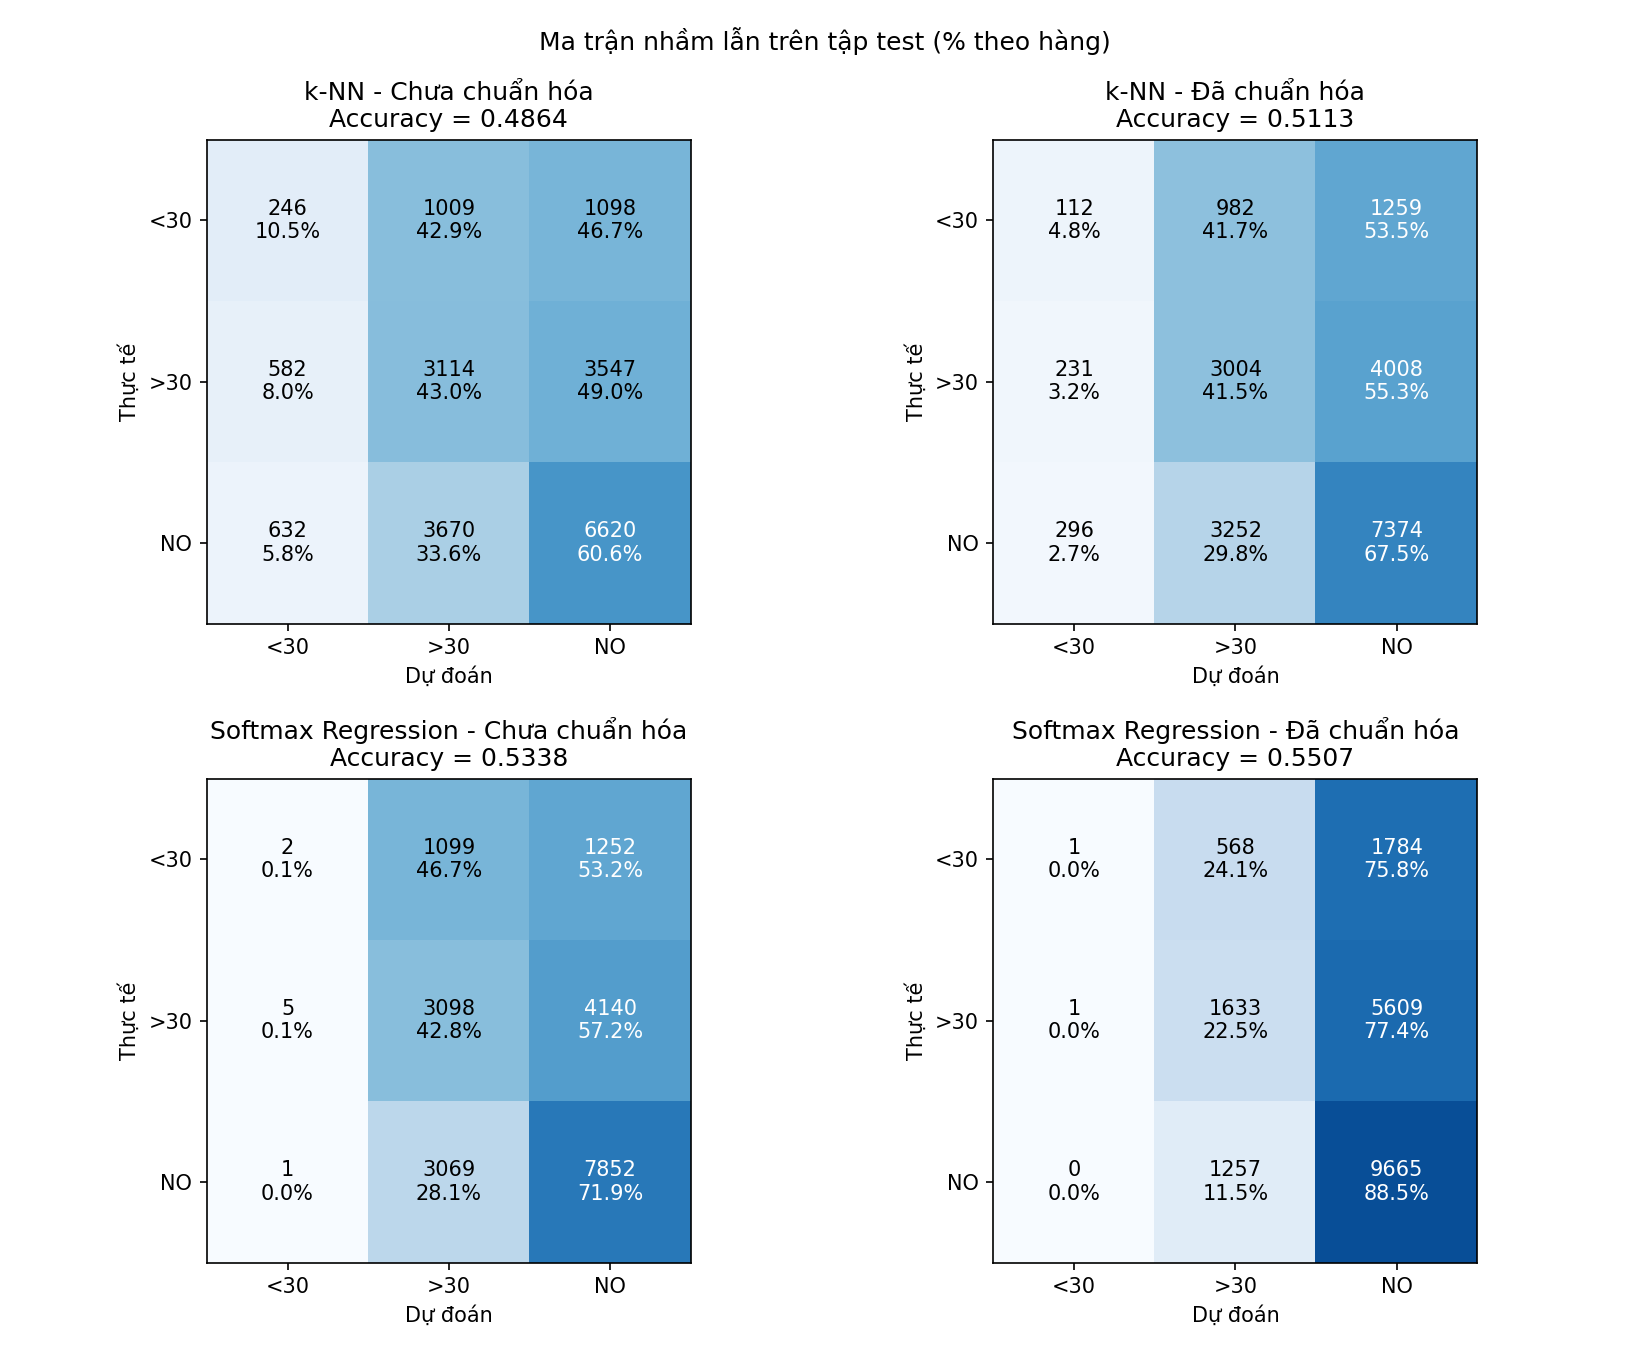

In [15]:
import pandas as pd
from IPython.display import Image, display
!python ../Dung/src/10_evaluation.py
display(pd.read_csv("output/accuracy_summary.csv"))
display(Image("output/confusion_matrices.png"))